# CNN para identificación del sistema dinámico — Horno Fusor

En lugar de usar una red LSTM (que procesa la secuencia paso a paso como si "recordara"), aquí usamos una **CNN — Red Neuronal Convolucional**.

Aunque las CNN se asocian con imágenes, funcionan muy bien en series de tiempo: en lugar de buscar patrones en píxeles, buscan **patrones temporales** dentro de la ventana de entrada.

La idea es la misma que con LSTM: dada una ventana de los últimos N instantes, predice la temperatura del siguiente paso.

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from scipy.optimize import curve_fit 
import os


# usar la GPU de Apple Silicon si está disponible
device = torch.device('mps' if torch.backends.mps.is_available() else 'cpu')
print('usando dispositivo:', device)

usando dispositivo: cpu


## 1. Carga y limpieza
Igual que en el LSTM: se carga, se interpolan los nulos de sensor_temp, y se calcula el error.

In [12]:
df = pd.read_csv('dataset_horno_fusor2.csv', parse_dates=['timestamp'])
df = df.sort_values('timestamp').reset_index(drop=True)
df['sensor_temp'] = df['sensor_temp'].interpolate(method='linear')
df['error'] = df['sensor_temp'] - df['setpoint']

# quitar los spikes extremos (el 1% más alto y más bajo)
q_low  = df['sensor_temp'].quantile(0.01)
q_high = df['sensor_temp'].quantile(0.99)
df = df[(df['sensor_temp'] > q_low) & (df['sensor_temp'] < q_high)].reset_index(drop=True)

features = ['sensor_temp', 'gas_flow', 'furnace_load', 'error', 'setpoint']
data = df[features].dropna().values
print('Shape del dataset limpio:', data.shape)

Shape del dataset limpio: (21167, 5)


## 2. Preprocesamiento: escalado y ventanas

Igual que con LSTM:
- **Escalamos** los datos para que todas las variables tengan la misma magnitud
- **Armamos ventanas** de tamaño `LOOKBACK`: cada muestra de entrenamiento es una secuencia de 5 horas y la etiqueta es la temperatura del paso siguiente
- **Split cronológico**: los primeros 80% del tiempo para entrenar, los últimos 20% para probar

In [13]:
LOOKBACK  = 30*10*3 # 5 horas
TRAIN_PCT = 0.8

scaler      = StandardScaler()
data_scaled = scaler.fit_transform(data)

def make_windows(arr, lookback):
    X, y = [], []
    for i in range(lookback, len(arr)):
        X.append(arr[i - lookback:i])
        y.append(arr[i, 0])  # sensor_temp del siguiente paso
    return np.array(X), np.array(y)

X, y = make_windows(data_scaled, LOOKBACK)

split   = int(len(X) * TRAIN_PCT)
X_train = torch.tensor(X[:split], dtype=torch.float32).to(device)
y_train = torch.tensor(y[:split], dtype=torch.float32).to(device)
X_test  = torch.tensor(X[split:], dtype=torch.float32).to(device)
y_test  = torch.tensor(y[split:], dtype=torch.float32).to(device)

# la CNN espera los datos en formato (batch, canales, longitud)
# en este caso: (muestras, variables, pasos de tiempo)
X_train = X_train.permute(0, 2, 1)
X_test  = X_test.permute(0, 2, 1)

print('Train:', X_train.shape, '  Test:', X_test.shape)

Train: torch.Size([16213, 5, 900])   Test: torch.Size([4054, 5, 900])


## 3. Arquitectura de la CNN

La red tiene tres bloques principales:

1. **Capas convolucionales**: aplican filtros que detectan patrones locales en la secuencia temporal (subidas, bajadas, oscilaciones). Es como un "detector de formas" en el tiempo.
2. **Capa de pooling**: resume la información más importante de cada filtro.
3. **Capas fully connected**: toman esos patrones detectados y producen la predicción final de temperatura.

In [14]:
class CNNModel(nn.Module):
    def __init__(self, input_channels, seq_len):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv1d(input_channels, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv1d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.AvgPool1d(kernel_size=2)
        )
        # calcular la dim aplastada con un forward de prueba (no hardcodea 128*15)
        with torch.no_grad():
            dummy = torch.zeros(1, input_channels, seq_len)
            flat_dim = self.conv(dummy).flatten(1).shape[1]
        self.fc = nn.Sequential(
            nn.Flatten(),
            nn.Linear(flat_dim, 64),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(64, 1)
        )

    def forward(self, x):
        return self.fc(self.conv(x)).squeeze()

model     = CNNModel(input_channels=len(features), seq_len=LOOKBACK).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
criterion = nn.MSELoss()
print(model)

CNNModel(
  (conv): Sequential(
    (0): Conv1d(5, 64, kernel_size=(3,), stride=(1,), padding=(1,))
    (1): ReLU()
    (2): Conv1d(64, 128, kernel_size=(3,), stride=(1,), padding=(1,))
    (3): ReLU()
    (4): AvgPool1d(kernel_size=(2,), stride=(2,), padding=(0,))
  )
  (fc): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=57600, out_features=64, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.2, inplace=False)
    (4): Linear(in_features=64, out_features=1, bias=True)
  )
)


## 4. Entrenamiento

Incluye **early stopping**: si el modelo deja de mejorar durante 15 épocas seguidas, se detiene solo y guarda la mejor versión. Esto evita sobreentrenamiento.

In [15]:
# entrenamiento
EPOCHS, BATCH_SIZE, patience = 150, 64, 50
train_losses, test_losses = [], []
best_loss, counter = float('inf'), 0
CKPT_DIR = 'checkpoints'

if os.path.exists('best_cnn.pt'):
    print('Modelo ya entrenado encontrado (best_cnn.pt) — cargando en lugar de entrenar.')
    model.load_state_dict(torch.load('best_cnn.pt'))
    model.eval()

else:
    # carpeta para guardar las épocas
    os.makedirs(CKPT_DIR, exist_ok=True)

    for epoch in range(EPOCHS):
        model.train()
        perm       = torch.randperm(X_train.size(0))
        epoch_loss = 0
        for i in range(0, X_train.size(0), BATCH_SIZE):
            idx    = perm[i:i + BATCH_SIZE]
            xb, yb = X_train[idx], y_train[idx]
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            optimizer.step()
            epoch_loss += loss.item() * xb.size(0) # ponderado por tamaño de batch

        train_loss = epoch_loss / X_train.size(0) # MSE promedio por muestra
        train_losses.append(train_loss)

        # test loss (validación)
        model.eval()
        with torch.no_grad():
            test_loss = criterion(model(X_test), y_test).item()
        test_losses.append(test_loss)

        # guardar la época
        torch.save(model.state_dict(), f'{CKPT_DIR}/cnn_epoch_{epoch+1:03d}.pt')

        # early stopping sobre test_loss
        if test_loss < best_loss:
            best_loss, counter = test_loss, 0
            torch.save(model.state_dict(), 'best_cnn.pt')
            
        else:
            counter += 1
            if counter >= patience:
                print(f'early stopping en época {epoch+1}')
                break

        print(f'Época {epoch+1}  |  Train: {train_loss:.4f}  |  Test: {test_loss:.4f}')

    model.load_state_dict(torch.load('best_cnn.pt'))
    print(f'\népocas guardadas en ./{CKPT_DIR}/')

    # gráfica train vs test 
    plt.figure(figsize=(8, 3))
    plt.plot(train_losses, color='steelblue',  label='Train')
    plt.plot(test_losses,  color='darkorange', label='Test (validación)')
    plt.axvline(np.argmin(test_losses), ls='--', c='gray', label='mejor época')
    plt.title('Curva de pérdida — CNN')
    plt.xlabel('Época')
    plt.ylabel('MSE')
    plt.legend()
    plt.tight_layout()

    # guardar losses para reproducir la gráfica sin reentrenar
    pd.DataFrame({
        'epoch':       range(1, len(train_losses) + 1),
        'train_loss':  train_losses,
        'test_loss':   test_losses
    }).to_csv('cnn_losses.csv', index=False)
    print('losses guardados en cnn_losses.csv')

Modelo ya entrenado encontrado (best_cnn.pt) — cargando en lugar de entrenar.


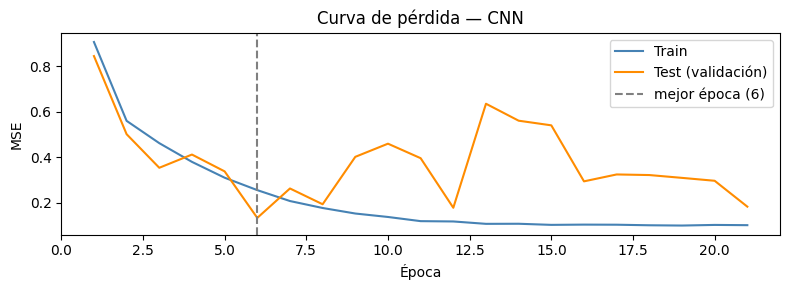


mejor época: 6  |  Train: 0.2559  |  Test: 0.1342


In [16]:
# gráfica de losses desde un archivo (sin reentrenar)
losses_df = pd.read_csv('cnn_losses.csv')

plt.figure(figsize=(8, 3))
plt.plot(losses_df['epoch'], losses_df['train_loss'], color='steelblue',  label='Train')
plt.plot(losses_df['epoch'], losses_df['test_loss'],  color='darkorange', label='Test (validación)')
plt.axvline(losses_df['test_loss'].idxmin() + 1, ls='--', c='gray', label=f"mejor época ({losses_df['test_loss'].idxmin() + 1})")
plt.title('Curva de pérdida — CNN')
plt.xlabel('Época')
plt.ylabel('MSE')
plt.legend()
plt.tight_layout()
plt.show()

print(f"\nmejor época: {losses_df['test_loss'].idxmin() + 1}  |  Train: {losses_df.loc[losses_df['test_loss'].idxmin(), 'train_loss']:.4f}  |  Test: {losses_df['test_loss'].min():.4f}")

## 5. Evaluación

Medimos qué tan bien predice el modelo en datos que nunca vio durante el entrenamiento.

RMSE: 0.6019 °C
MAE : 0.4009 °C
R²  : 0.989272


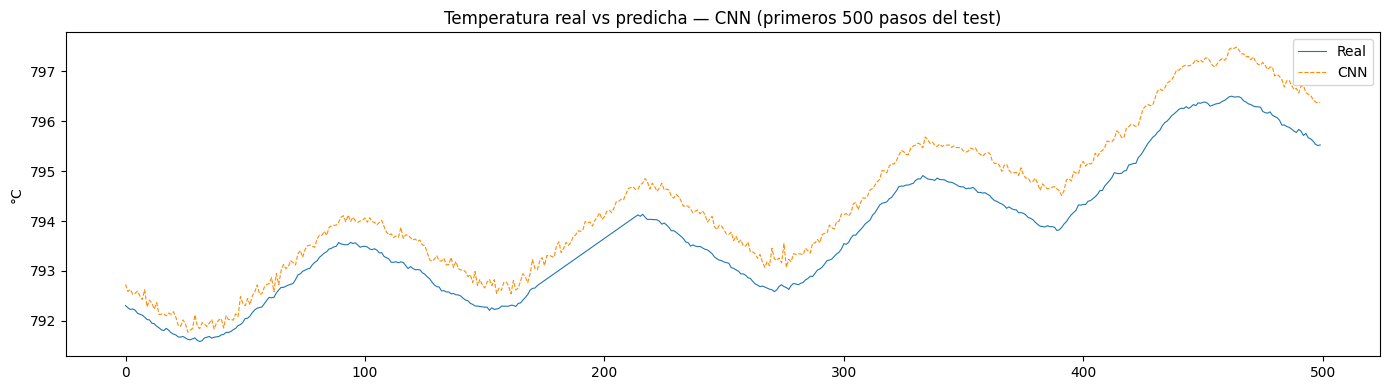

In [17]:
model.eval()
with torch.no_grad():
    pred_scaled = model(X_test).cpu().numpy()
    real_scaled = y_test.cpu().numpy()

mean_temp = scaler.mean_[0]
std_temp  = scaler.scale_[0]
pred_temp = pred_scaled * std_temp + mean_temp
real_temp = real_scaled * std_temp + mean_temp

rmse = np.sqrt(mean_squared_error(real_temp, pred_temp))
mae  = mean_absolute_error(real_temp, pred_temp)
r2   = r2_score(real_temp, pred_temp)

print(f'RMSE: {rmse:.4f} °C')
print(f'MAE : {mae:.4f} °C')
print(f'R²  : {r2:.6f}')

plt.figure(figsize=(14, 4))
plt.plot(real_temp[:500], label='Real', lw=0.8)
plt.plot(pred_temp[:500], label='CNN', lw=0.8, linestyle='--', color='darkorange')
plt.title('Temperatura real vs predicha — CNN (primeros 500 pasos del test)')
plt.ylabel('°C')
plt.legend()
plt.tight_layout()

## 6. Respuesta al escalón y ajuste FOPDT

Simulamos qué pasa cuando el gas flow sube de golpe veinte unidades. La curva que produce el modelo la usamos para ajustar un **modelo FOPDT** (First Order Plus Dead Time) — el sistema de primer orden con retardo que describe la dinámica del horno.

De ahí extraemos tres parámetros:
- **K** — ganancia del proceso (cuánto sube la temperatura por unidad de cambio en el setpoint)
- **τ (tau)** — constante de tiempo (qué tan rápido responde el horno)
- **L** — retardo (cuánto tarda en empezar a reaccionar)

K = 0.2319 °C/u_gas   τ = 499s (0.14 h)   L = 70s


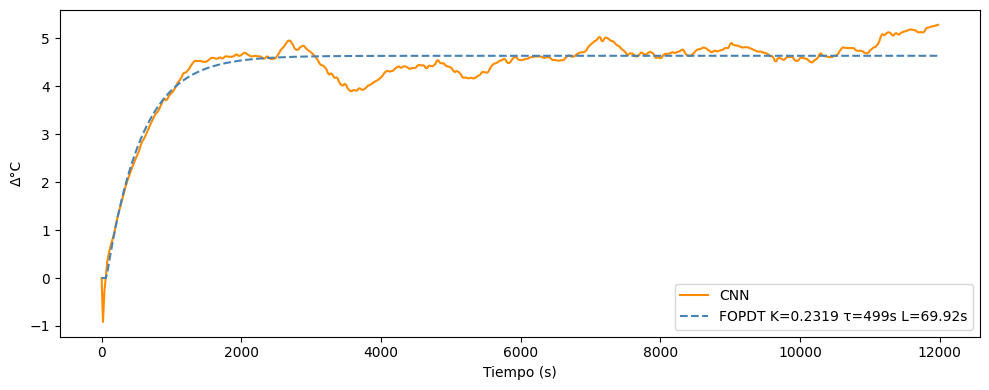

In [21]:
# respuesta al escalón -> FOPDT -> G(s) 
# método diferencial (cancela el drift de la CNN)

U_COL = 1  # gas_flow = entrada de planta U
baseline_idx = 1000
DU = 20.0 # magnitud del escalón en unidades de gas
N_STEPS = 600 
Ts = 20.0

# función que corre la CNN encadenada, con o sin escalón
def run_response(step_on, du=DU, n=N_STEPS):
    base = data_scaled[baseline_idx - LOOKBACK:baseline_idx].copy()
    w = base.copy()                       # ventana sin escalón al inicio
    gas_step = du / scaler.scale_[U_COL]
    resp = []
    model.eval()
    with torch.no_grad():
        for k in range(n):
            x  = torch.tensor(w[np.newaxis], dtype=torch.float32).permute(0,2,1).to(device)
            yh = model(x).item()
            t  = yh * std_temp + mean_temp
            resp.append(t)
            nr = w[-1].copy()
            nr[0] = (t - mean_temp) / std_temp
            if step_on:
                nr[U_COL] = base[-1, U_COL] + gas_step   # gas elevado en el paso NUEVO
            w = np.vstack([w[1:], nr])
    return np.array(resp)

# dos corridas: con y sin escalón 
r_off = run_response(step_on=False) # respuesta libre (drift puro de la CNN)
r_on  = run_response(step_on=True) # respuesta forzada + drift
t_step = np.arange(N_STEPS) * Ts

# respuesta con escalón menos drift
dy = r_on - r_off

# ajuste FOPDT sobre la respuesta diferencial
def fopdt_delta(t, K, tau, L):
    return np.where(t < L, 0.0, K * DU * (1 - np.exp(-(t - L) / tau)))

lb = [0.0, 60, 0] # K>0: más gas => más temp (físico)
ub = [1.0, 40000, 2000]
p0 = [dy[-1] / DU, 3000.0, 100.0]


mask = t_step <= 12000  # tomar en cuenta 9k segundos para la fopdt
popt, _ = curve_fit(fopdt_delta, t_step[mask], dy[mask], p0=p0, bounds=(lb, ub))

K_est, tau_est, L_est = popt
print(f'K = {K_est:.4f} °C/u_gas   τ = {tau_est:.0f}s ({tau_est/3600:.2f} h)   L = {L_est:.0f}s')

# gráfica del ajuste 
plt.figure(figsize=(10,4))
plt.plot(t_step, dy, color='darkorange', lw=1.5, label='CNN')
plt.plot(t_step, fopdt_delta(t_step, *popt), '--', color='steelblue', lw=1.5,
         label=f'FOPDT K={K_est:.4f} τ={tau_est:.0f}s L={L_est:.2f}s')
plt.xlabel('Tiempo (s)')
plt.ylabel('Δ°C')
plt.legend()
plt.tight_layout()
plt.show()

In [19]:
# G(s) en todas sus formas y toda su info


# G(s) racional con Padé(1) del retardo

# K y L sí se toman de la CNN
num = [K_est] 
tau_est = 10000
den = [tau_est, 1]

num_p = [-L_est/2, 1] # Padé(1):  e^(-Ls) ≈ (1 - L/2·s)/(1 + L/2·s)
den_p = [ L_est/2, 1]

num_full = np.polymul(num, num_p)
den_full = np.polymul(den, den_p)

# impresión
print('   G(s) — Función de transferencia del horno (CNN)')
print(f'\n  Ganancia    K   = {K_est:.4f} °C/u_gas')
print(f'  Const. tiempo τ = {tau_est:.1f} s  ({tau_est/60:.2f} min)')
print(f'  Retardo      L   = {L_est:.1f} s  ({L_est/60:.2f} min)\n')

print('  Forma FOPDT:')
print(f'                {K_est:.3f}')
print(f'    G(s) = ───────────────── · e^(-{L_est:.1f}s)')
print(f'              {tau_est:.1f}·s + 1\n')

print('  Forma racional (Padé 1) — lista para Simulink/step:')
print(f'           {num_full[0]:.3f}·s + {num_full[1]:.3f}')
print('    G(s) = ──────────────────────────')
print(f'         {den_full[0]:.2f}·s² + {den_full[1]:.2f}·s + {den_full[2]:.2f}')

# forma coef de s² = 1
n0 = num_full[0] / den_full[0]
n1 = num_full[1] / den_full[0]
d1 = den_full[1] / den_full[0]
d2 = den_full[2] / den_full[0]

print('  Forma racional (Padé 1) — con s² solita')
print(f'           {n0:.4g}·s + {n1:.4g}')
print('    G(s) = ──────────────────────────')
print(f'              s² + {d1:.4g}·s + {d2:.4g}')



# info
print(f'\ndy: arranca en {dy[0]:.4f}, termina en {dy[-1]:.4f}, \na 1/3 del camino (paso {N_STEPS//3}): {dy[N_STEPS//3]:.4f}')
print('\n¿en qué paso llega al 63% del valor final?')
target = 0.63 * dy[-1]
idx_63 = np.argmax(dy >= target)
print(f'   paso {idx_63}  ->  τ ≈ {idx_63 * 20} s ({idx_63*20/3600:.2f} h)')


poles = np.roots([1, d1, d2])
print('\nPolos:', poles)
print('τ aprox (1/|polo real más lento|):', 1/np.min(np.abs(poles.real)), 's')
print('Ganancia DC G(0) = n1/d2 =', n1/d2)
print('K esperado (del barrido):', K_est)

   G(s) — Función de transferencia del horno (CNN)

  Ganancia    K   = 0.2319 °C/u_gas
  Const. tiempo τ = 10000.0 s  (166.67 min)
  Retardo      L   = 69.9 s  (1.17 min)

  Forma FOPDT:
                0.232
    G(s) = ───────────────── · e^(-69.9s)
              10000.0·s + 1

  Forma racional (Padé 1) — lista para Simulink/step:
           -8.107·s + 0.232
    G(s) = ──────────────────────────
         349601.18·s² + 10034.96·s + 1.00
  Forma racional (Padé 1) — con s² solita
           -2.319e-05·s + 6.633e-07
    G(s) = ──────────────────────────
              s² + 0.0287·s + 2.86e-06

dy: arranca en 0.0000, termina en 5.2831, 
a 1/3 del camino (paso 200): 4.1849

¿en qué paso llega al 63% del valor final?
   paso 37  ->  τ ≈ 740 s (0.21 h)

Polos: [-2.86040226e-02 -1.00000000e-04]
τ aprox (1/|polo real más lento|): 10000.0 s
Ganancia DC G(0) = n1/d2 = 0.23187925417876107
K esperado (del barrido): 0.2318792541787611
